# DSA4212 | Person 4 – Ellipsoid effective dimension

**All-in-one Jupyter notebook**. Every function, optimiser, parameter, test, experiment loop, CSV exporter and plot is in this file. No `shared/` directory or separate `.py` scripts are needed.

**Research question** (assignment, p. 4)  
Can GP Bayesian Optimisation (Expected Improvement) or CMA-ES exploit low effective dimension when relevant variables have unequal sensitivities?

- Ambient dimension fixed at **D = 20** for all optimisations.
- Effective dimensions **d = 2, 5, 10, 20**; only the first d coordinates influence the function.
- Bounds **[-5, 5]** in every coordinate; global minimum **0** when the first d coordinates equal 1.
- Ellipsoid weights `np.geomspace(1, 100, d)`, yielding a 100:1 sensitivity ratio.
- **100 objective evaluations per run**, for seeds **0–4**.
- **GP-BO and CMA-ES** for each setting, **40 runs** and **4,000 objective calls** if all runs finish their budgets.

The assignment fixes these experimental parameters but **does not prescribe optimiser-specific settings**. The hyperparameters below are *provisional group defaults* taken from the earlier shared-code prototype. Agree on them with the other three members before using the results for comparisons.

## 0. Install dependencies

Run the next cell once in your notebook environment. Python packages are external dependencies, but all **experiment code** lives inside this notebook. If dependencies are already installed, you may skip the cell.

In [1]:
#%pip install -q numpy pandas scipy scikit-learn matplotlib cma


## 1. Import packages and specify shared pilot settings

Settings are explicitly shown in one place. In particular, BO's random starting observations and CMA-ES's last incomplete generation count toward the 100-call budget. The chosen acquisition-search effort is a pilot trade-off, not an assignment requirement.

In [2]:
# Standard library
from dataclasses import asdict, dataclass, replace
import json
import platform
import time
import traceback
import warnings
from pathlib import Path

# Numerical computing and optimisation
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.stats import norm

# Gaussian-process Bayesian optimisation
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

# CMA-ES and plotting
import cma
import matplotlib.pyplot as plt
from IPython.display import display, Image


"""Shared group settings. Agree on these BEFORE producing comparison results.

The PDF specifies budgets, bounds, dimensions, seeds, functions and conditioning.
The optimiser-specific settings below are provisional choices for the pilot.
All members should import this one config instead of copying/tweaking it.
"""


@dataclass(frozen=True)
class PilotConfig:
    D: int = 20
    effective_dimensions: tuple = (2, 5, 10, 20)
    seeds: tuple = (0, 1, 2, 3, 4)
    budget: int = 100
    lower_bound: float = -5.0
    upper_bound: float = 5.0

    # GP Bayesian optimisation, expected improvement, minimise objective
    bo_initial_points: int = 10
    bo_kernel: str = "ConstantKernel * Matern(nu=2.5, ARD=True)"
    bo_gp_alpha: float = 1e-6  # numerical jitter (deterministic test function)
    bo_lengthscale_min: float = 0.1
    bo_lengthscale_max: float = 10.0
    bo_hyperparam_refit_interval: int = 10
    bo_gp_optimizer_restarts: int = 0
    bo_ei_xi: float = 0.0
    bo_acq_random_candidates: int = 256
    bo_acq_local_starts: int = 1
    bo_acq_local_maxiter: int = 15

    # CMA-ES: full ambient 20-space, fixed population size across d
    cma_initial_mean: float = 0.0
    cma_sigma0: float = 2.0
    cma_popsize: int = 10
    cma_boundary_handling: str = "pycma bounds / default BoundTransform"
    cma_partial_generation: str = "Evaluate remaining points; do not tell partial generation"

    def as_dict(self):
        return asdict(self)


CONFIG = PilotConfig()




print('Config loaded. D =', CONFIG.D, '; effective dimensions =', CONFIG.effective_dimensions)
display(pd.Series(CONFIG.as_dict(), name='Pilot setting').to_frame())


Config loaded. D = 20 ; effective dimensions = (2, 5, 10, 20)


,Pilot setting
D,20
effective_dimensions,"(2, 5, 10, 20)"
seeds,"(0, 1, 2, 3, 4)"
budget,100
lower_bound,-5.0
upper_bound,5.0
bo_initial_points,10
bo_kernel,"ConstantKernel * Matern(nu=2.5, ARD=True)"
bo_gp_alpha,0.000001
bo_lengthscale_min,0.1


## 2. Define and unit-test the Ellipsoid objective

For `x` with **20 coordinates**:

\[
 f(x) = \sum_{i=1}^{d} \lambda_i (x_i-1)^2,\qquad
 \lambda_i = 100^{(i-1)/(d-1)} \quad (d\geq2).
\]

Only `x[:d]` affects the function, regardless of what the remaining `20-d` values are. The test checks the known global minimum, weight endpoints, conditioning, input shape, and independence from irrelevant variables.

In [3]:
"""Objective functions with the same signature for all members."""


def ellipsoid(x, D=20, d=2):
    """Ellipsoid in D dimensions, with only first d variables relevant.

    f(x) = sum_{i=1}^d lambda_i * (x_i - 1)^2
    lambda = np.geomspace(1, 100, d).
    Global minimum = 0 when the first d coordinates are 1.
    """
    if not (2 <= d <= D):
        raise ValueError("Require 2 <= d <= D")
    x = np.asarray(x, dtype=float)
    if x.shape != (D,):
        raise ValueError(f"Expected x with shape ({D},), got {x.shape}")
    if not np.all(np.isfinite(x)):
        raise ValueError("All inputs must be finite")
    weights = np.geomspace(1.0, 100.0, d)
    return float(np.sum(weights * (x[:d] - 1.0) ** 2))


def sphere(x, D=20, d=2):
    """Included so Person 3 can use the identical optimiser implementations."""
    if not (1 <= d <= D):
        raise ValueError("Require 1 <= d <= D")
    x = np.asarray(x, dtype=float)
    if x.shape != (D,):
        raise ValueError(f"Expected shape ({D},), got {x.shape}")
    return float(np.sum((x[:d] - 1.0) ** 2))


def check_ellipsoid(D=20, d=2):
    """Assert objective optimum, irrelevance and weight endpoints."""
    weights = np.geomspace(1.0, 100.0, d)
    assert len(weights) == d
    assert np.isclose(weights[0], 1.0)
    assert np.isclose(weights[-1], 100.0)
    assert np.all(np.diff(weights) > 0)
    assert np.isclose(weights[-1] / weights[0], 100.0)

    xopt = np.zeros(D)
    xopt[:d] = 1.0
    assert np.isclose(ellipsoid(xopt, D, d), 0.0)

    x = np.linspace(-4.0, 4.0, D)
    modified = x.copy()
    modified[d:] = 5.0
    assert np.isclose(ellipsoid(x, D, d), ellipsoid(modified, D, d))

    # Individual coordinate deviations of 1 should cost precisely lambda_i.
    for j in range(d):
        xj = xopt.copy()
        xj[j] = 2.0
        assert np.isclose(ellipsoid(xj, D, d), weights[j])
    return weights


In [4]:
objective_checks = []
for d in CONFIG.effective_dimensions:
    weights = check_ellipsoid(CONFIG.D, d)
    x_opt = np.zeros(CONFIG.D)
    x_opt[:d] = 1.0
    objective_checks.append({
        "D": CONFIG.D, "d": d, "irrelevant_variables": CONFIG.D - d,
        "minimum": ellipsoid(x_opt, D=CONFIG.D, d=d),
        "first_weight": weights[0], "last_weight": weights[-1],
        "weight_ratio": weights[-1] / weights[0],
    })
display(pd.DataFrame(objective_checks))
print('Objective checks passed for all four effective dimensions.')


,D,d,irrelevant_variables,minimum,first_weight,last_weight,weight_ratio
0,20,2,18,0.0,1.0,100.0,100.0
1,20,5,15,0.0,1.0,100.0,100.0
2,20,10,10,0.0,1.0,100.0,100.0
3,20,20,0,0.0,1.0,100.0,100.0


Objective checks passed for all four effective dimensions.


## 3. Implement both optimisers

**GP-BO** uses a Gaussian process with a Matérn-5/2 kernel and independent lengthscales (ARD), Expected Improvement for **minimisation**, 10 random initial observations and bounded acquisition optimisation. Hyperparameter refits happen every 10 additional observations, with the learned kernel reused between refits.

**CMA-ES** uses the standard Python `cma` package, starts at a zero mean with initial step size 2 and population 10, and uses its box-bound handler. For a partial last generation, the remaining candidates are evaluated and logged but not supplied to an incomplete `tell` update. Seed 0 is mapped to the *pycma* seed 1 (and analogously 1→2, etc.) because pycma may treat 0 as a request for a random seed. **All group members should use the same seed mapping.**

No candidate the optimisers evaluate lies outside the required box. Gaussian-process predictions and internal acquisition optimisation **do not count as objective evaluations**.

In [5]:
"""Shared GP-BO (EI) and CMA-ES implementations, with exact objective accounting."""


def expected_improvement(gp, X, best_y, xi):
    """EI for MINIMISATION: E[max(0, best_y - f(x) - xi)]."""
    mu, std = gp.predict(np.atleast_2d(X), return_std=True)
    std = np.maximum(std, 0.0)
    improvement = best_y - mu - xi
    with np.errstate(divide="ignore", invalid="ignore"):
        z = np.divide(improvement, std, out=np.zeros_like(std), where=std > 1e-12)
        ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    # For deterministic predictions, there is no positive uncertainty bonus.
    return np.where(std > 1e-12, np.maximum(ei, 0.0), np.maximum(improvement, 0.0))


def _choose_ei_candidate(gp, rng, X_observed, y_observed, cfg):
    D = X_observed.shape[1]
    bounds = [(cfg.lower_bound, cfg.upper_bound)] * D
    random_points = rng.uniform(cfg.lower_bound, cfg.upper_bound,
                                size=(cfg.bo_acq_random_candidates, D))
    scores = expected_improvement(gp, random_points, float(y_observed.min()), cfg.bo_ei_xi)
    best_index = int(np.argmax(scores))
    best_x = random_points[best_index].copy()
    best_ei = float(scores[best_index])

    # Multistart local optimisation of EI. These GP predictions do NOT count
    # as objective evaluations; only calls through the recorder do.
    starts = np.argsort(scores)[-cfg.bo_acq_local_starts:]
    for idx in starts:
        def negative_ei(z):
            return -float(expected_improvement(
                gp, np.asarray(z)[None, :], float(y_observed.min()), cfg.bo_ei_xi
            )[0])
        result = minimize(
            negative_ei, random_points[idx], method="L-BFGS-B", bounds=bounds,
            options={"maxiter": cfg.bo_acq_local_maxiter},
        )
        candidate = np.clip(result.x, cfg.lower_bound, cfg.upper_bound)
        score = -negative_ei(candidate)
        if score > best_ei:
            best_x, best_ei = candidate, score

    # Prevent repeated objective calls from numerical acquisition convergence.
    if np.min(np.linalg.norm(X_observed - best_x[None, :], axis=1)) < 1e-8:
        best_x = rng.uniform(cfg.lower_bound, cfg.upper_bound, size=D)
    return best_x


def run_gp_bo(objective, record, cfg, seed):
    """Sequential GP-BO, with initial random design included in the budget."""
    rng = np.random.default_rng(seed)
    D = cfg.D
    init_count = min(cfg.bo_initial_points, cfg.budget)
    if init_count < 2:
        raise ValueError("BO requires at least 2 initial evaluations")
    X = []
    y = []
    for x in rng.uniform(cfg.lower_bound, cfg.upper_bound, size=(init_count, D)):
        X.append(x.copy())
        y.append(record(x))

    fitted_kernel = None
    while len(y) < cfg.budget:
        n_since_init = len(y) - init_count
        refit_hyperparameters = (
            fitted_kernel is None
            or n_since_init % cfg.bo_hyperparam_refit_interval == 0
        )
        if refit_hyperparameters:
            kernel = ConstantKernel(1.0, (0.01, 100.0)) * Matern(
                length_scale=np.ones(D),
                length_scale_bounds=(cfg.bo_lengthscale_min, cfg.bo_lengthscale_max),
                nu=2.5,
            ) if fitted_kernel is None else fitted_kernel
            gp_optimizer = "fmin_l_bfgs_b"
        else:
            kernel = fitted_kernel
            gp_optimizer = None

        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=cfg.bo_gp_alpha,
            normalize_y=True,
            optimizer=gp_optimizer,
            n_restarts_optimizer=cfg.bo_gp_optimizer_restarts if gp_optimizer else 0,
            random_state=seed,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            gp.fit(np.asarray(X), np.asarray(y))
        fitted_kernel = gp.kernel_
        next_x = _choose_ei_candidate(gp, rng, np.asarray(X), np.asarray(y), cfg)
        X.append(next_x.copy())
        y.append(record(next_x))
    return "budget_exhausted"


def run_cma_es(objective, record, cfg, seed):
    """Official pycma ask/tell loop, including explicitly logged partial final generation."""
    es = cma.CMAEvolutionStrategy(
        np.full(cfg.D, cfg.cma_initial_mean), cfg.cma_sigma0,
        {
            "bounds": [cfg.lower_bound, cfg.upper_bound],
            "seed": seed + 1,  # pycma seed=0 can randomise; explicit 1..5 mapping
            "popsize": cfg.cma_popsize,
            "verbose": -9,
            "verb_disp": 0,
            "verb_log": 0,
        },
    )
    n = 0
    while n < cfg.budget and not es.stop():
        solutions = es.ask()  # typically cfg.cma_popsize proposed at once
        remaining = cfg.budget - n
        to_evaluate = solutions[:remaining]
        values = [record(np.asarray(x)) for x in to_evaluate]
        n += len(to_evaluate)
        if len(to_evaluate) < len(solutions):
            # Do not call tell on incomplete final generation. All actual
            # evaluations are retained and counted toward the 100-call cap.
            return "budget_exhausted_partial_generation"
        es.tell(solutions, values)

    if n == cfg.budget:
        return "budget_exhausted"
    return "cma_internal_stop:" + str(es.stop())


## 4. Run one optimisation and log every objective call

The recorder stores the evaluation index, all 20 coordinates (`x_json`), objective value, running best and elapsed time. Each run also stores its termination reason, actual count, runtime, settings, and any error traceback.

In [6]:
"""Run Person 4's Ellipsoid effective-dimension pilot and export all raw results.

Execute the smoke-test and full-experiment cells below.
All code and imports are contained in this notebook.
"""




def execute_one(cfg, d, algorithm, seed):
    """Return raw evaluation rows and run metadata, including partial failed runs."""
    history = []
    started = time.perf_counter()
    best = float("inf")
    run_id = f"P4_Ellipsoid_D{cfg.D}_d{d}_{algorithm}_seed{seed}"

    def objective(x):
        return ellipsoid(x, D=cfg.D, d=d)

    def record(x):
        nonlocal best
        x = np.asarray(x, dtype=float)
        if x.shape != (cfg.D,):
            raise ValueError(f"Optimiser returned {x.shape}, expected {(cfg.D,)}")
        if np.any(x < cfg.lower_bound - 1e-9) or np.any(x > cfg.upper_bound + 1e-9):
            raise ValueError("Optimiser evaluated an out-of-bounds point")
        val = objective(x)
        best = min(best, val)
        history.append({
            "experiment": "person4_ellipsoid_effective",
            "run_id": run_id,
            "function": "Ellipsoid",
            "algorithm": algorithm,
            "D": cfg.D,
            "d": d,
            "D/d": f"{cfg.D}/{d}",
            "seed": seed,
            "evaluation": len(history) + 1,
            "objective_value": val,
            "best_value": best,
            "elapsed_seconds": time.perf_counter() - started,
            "x_json": json.dumps(x.tolist()),
        })
        return val

    error_trace = None
    try:
        if algorithm == "GP-BO":
            reason = run_gp_bo(objective, record, cfg, seed)
        elif algorithm == "CMA-ES":
            reason = run_cma_es(objective, record, cfg, seed)
        else:
            raise ValueError(f"Unknown algorithm: {algorithm}")
    except Exception:
        error_trace = traceback.format_exc()
        reason = "error"

    metadata = {
        "run_id": run_id,
        "experiment": "person4_ellipsoid_effective",
        "function": "Ellipsoid",
        "algorithm": algorithm,
        "D": cfg.D,
        "d": d,
        "seed": seed,
        "best_value": best if history else None,
        "n_evals": len(history),
        "total_runtime_seconds": time.perf_counter() - started,
        "termination_reason": reason,
        "error_traceback": error_trace,
        "weights": np.geomspace(1.0, 100.0, d).tolist(),
        "settings": cfg.as_dict(),
    }
    return history, metadata


def run_experiments(cfg=CONFIG, out_dir="results/person4", algorithms=("GP-BO", "CMA-ES")):
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    for d in cfg.effective_dimensions:
        weights = check_ellipsoid(cfg.D, d)
        print(f"Objective check OK: D={cfg.D}, d={d}, weights=[{weights[0]:.1f}, ..., {weights[-1]:.1f}]")

    cma_version = cma.__version__

    settings = {
        "pilot_config": cfg.as_dict(),
        "packages": {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "scipy": scipy.__version__,
                     "scikit-learn": sklearn.__version__, "cma": cma_version},
        "comparability_note": "Share the same optimiser implementations and settings across all four members.",
    }
    (out / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")

    raw_path = out / "evaluations.csv"
    meta_path = out / "run_metadata.jsonl"
    # Fresh run: truncate previous results, then checkpoint after each run.
    raw_path.unlink(missing_ok=True)
    meta_path.unlink(missing_ok=True)
    all_meta = []
    for algorithm in algorithms:
        for d in cfg.effective_dimensions:
            for seed in cfg.seeds:
                rows, meta = execute_one(cfg, d, algorithm, seed)
                if rows:
                    pd.DataFrame(rows).to_csv(raw_path, mode="a", index=False,
                                              header=not raw_path.exists())
                with meta_path.open("a", encoding="utf-8") as stream:
                    stream.write(json.dumps(meta) + "\n")
                all_meta.append(meta)
                print(f"{algorithm:6s} D={cfg.D:2d} d={d:2d} seed={seed} "
                      f"n={meta['n_evals']:3d} best={str(meta['best_value']):>12s} "
                      f"time={meta['total_runtime_seconds']:.1f}s "
                      f"reason={meta['termination_reason']}", flush=True)

    summary = pd.DataFrame([{k: v for k, v in m.items() if k not in ("weights", "settings", "error_traceback")}
                            for m in all_meta])
    summary.to_csv(out / "run_summary.csv", index=False)
    if raw_path.exists():
        raw = pd.read_csv(raw_path)
        plot_results(raw, out / "ellipsoid_effective_curves.png", cfg)
    print(f"\nWrote results to {out.resolve()}")
    failures = summary[summary["termination_reason"] == "error"]
    if not failures.empty:
        print("WARNING: Some runs failed. See run_metadata.jsonl for full tracebacks.")
    return summary


def plot_results(raw, image_path, cfg):
    """Median best-so-far with min/max across seeds at each evaluation."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, d in zip(axes.flat, cfg.effective_dimensions):
        subset = raw[raw["d"] == d]
        for algorithm in ("GP-BO", "CMA-ES"):
            a = subset[subset["algorithm"] == algorithm]
            if a.empty:
                continue
            pivot = a.pivot(index="evaluation", columns="seed", values="best_value")
            median = pivot.median(axis=1)
            lo = pivot.min(axis=1)
            hi = pivot.max(axis=1)
            ax.plot(median.index, np.maximum(median.values, 1e-12), label=algorithm)
            ax.fill_between(median.index, np.maximum(lo.values, 1e-12),
                            np.maximum(hi.values, 1e-12), alpha=0.12)
        ax.set_title(f"Ellipsoid D={cfg.D}, d={d}")
        ax.set_xlabel("Objective evaluations (including initial BO points)")
        ax.set_ylabel("Best-so-far objective (log scale)")
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()
    fig.savefig(image_path, dpi=170)
    plt.close(fig)


## 5. Sanity checks for optimisation and logging

These checks are lightweight and run without starting the full 40-run experiment. They verify the objective, EI non-negativity and the 100-call bookkeeping logic. For the real CMA-ES implementation, the optional smoke test in the next section exercises the installed `cma` package.

In [7]:
# Basic deterministic checks
for d in CONFIG.effective_dimensions:
    w = check_ellipsoid(CONFIG.D, d)
    assert len(w) == d and np.isclose(w[-1] / w[0], 100.0)

# Expected Improvement must be nonnegative on well-formed Gaussian predictions.
class _ToyGP:
    def predict(self, X, return_std=False):
        return np.full(len(X), 0.1), np.full(len(X), 0.2)

candidate_ei = expected_improvement(_ToyGP(), np.zeros((3, CONFIG.D)), best_y=0.5, xi=0)
assert candidate_ei.shape == (3,)
assert np.all(candidate_ei >= 0)

# Shape checking protects against accidentally running BO in d dimensions.
try:
    ellipsoid(np.zeros(2), D=CONFIG.D, d=2)
except ValueError:
    pass
else:
    raise AssertionError('The objective must reject input vectors with fewer than 20 coordinates.')

print('Basic sanity checks passed.')


Basic sanity checks passed.


## 6. Optional quick smoke test

Test one configuration and one random seed using **12 evaluations** per algorithm before starting the full pilot. These results go to `results/person4_smoke/` and are not part of the official 100-evaluation comparison.

Set `RUN_SMOKE_TEST = False` to skip.

In [8]:
RUN_SMOKE_TEST = True
if RUN_SMOKE_TEST:
    smoke_cfg = replace(
        CONFIG, effective_dimensions=(2,), seeds=(0,), budget=12,
        bo_initial_points=5, bo_acq_random_candidates=64,
        bo_acq_local_starts=1, bo_acq_local_maxiter=5,
    )
    smoke_summary = run_experiments(smoke_cfg, out_dir=Path('results/person4_smoke'))
    display(smoke_summary[["algorithm", "d", "seed", "n_evals", "best_value", "termination_reason"]])
    assert len(smoke_summary) == 2
    assert (smoke_summary["n_evals"] == 12).all(), 'Inspect smoke metadata for error details.'
    assert (smoke_summary["termination_reason"] != 'error').all(), 'Inspect smoke metadata for error details.'
    print('Both optimisers completed their 12-call smoke tests.')


Objective check OK: D=20, d=2, weights=[1.0, ..., 100.0]
GP-BO  D=20 d= 2 seed=0 n= 12 best=11.116702068825001 time=0.1s reason=budget_exhausted
CMA-ES D=20 d= 2 seed=0 n= 12 best=26.473522257675075 time=0.0s reason=budget_exhausted_partial_generation

Wrote results to C:\Users\quanh\OneDrive - National University of Singapore\Y4S1\DSA4212\Final Project\DSA4212-Proj\results\person4_smoke


,algorithm,d,seed,n_evals,best_value,termination_reason
0,GP-BO,2,0,12,11.116702,budget_exhausted
1,CMA-ES,2,0,12,26.473522,budget_exhausted_partial_generation


Both optimisers completed their 12-call smoke tests.


## 7. Full experiment – 40 runs × 100 evaluations

**Before running**, confirm that everyone has agreed on optimiser hyperparameters and has the same implementation. Change `RUN_FULL` to `True` to start. Results are exported after each run to `results/person4/`, allowing you to inspect completed runs if a later run fails. Re-running the full experiment from the beginning **overwrites** existing files in that output directory.

All 40 runs should have an actual evaluation count of 100 unless an optimiser stops early or raises an error. Do not silently remove such cases.

In [9]:
RUN_FULL = True  # Change to True after agreeing on settings with your team.
if RUN_FULL:
    full_summary = run_experiments(CONFIG, out_dir=Path('results/person4'))
    display(full_summary)
    print('Completed runs:', int((full_summary['n_evals'] == CONFIG.budget).sum()), '/ 40')
    print('Total evaluations recorded:', int(full_summary['n_evals'].sum()))


Objective check OK: D=20, d=2, weights=[1.0, ..., 100.0]
Objective check OK: D=20, d=5, weights=[1.0, ..., 100.0]
Objective check OK: D=20, d=10, weights=[1.0, ..., 100.0]
Objective check OK: D=20, d=20, weights=[1.0, ..., 100.0]
GP-BO  D=20 d= 2 seed=0 n=100 best=0.06718635220834202 time=9.4s reason=budget_exhausted
GP-BO  D=20 d= 2 seed=1 n=100 best=0.19002847325435754 time=35.9s reason=budget_exhausted
GP-BO  D=20 d= 2 seed=2 n=100 best=0.07785646523100785 time=21.3s reason=budget_exhausted
GP-BO  D=20 d= 2 seed=3 n=100 best=0.02709205033582196 time=39.6s reason=budget_exhausted
GP-BO  D=20 d= 2 seed=4 n=100 best=0.4431434305157523 time=42.4s reason=budget_exhausted
GP-BO  D=20 d= 5 seed=0 n=100 best=6.7488382808514364 time=41.6s reason=budget_exhausted
GP-BO  D=20 d= 5 seed=1 n=100 best=11.866104174981764 time=40.8s reason=budget_exhausted
GP-BO  D=20 d= 5 seed=2 n=100 best=3.7919001771411978 time=11.1s reason=budget_exhausted
GP-BO  D=20 d= 5 seed=3 n=100 best=6.14493705086021 tim

,run_id,experiment,function,algorithm,D,d,seed,best_value,n_evals,total_runtime_seconds,termination_reason
0,P4_Ellipsoid_D20_d2_GP-BO_seed0,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,2,0,0.067186,100,9.441038,budget_exhausted
1,P4_Ellipsoid_D20_d2_GP-BO_seed1,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,2,1,0.190028,100,35.922461,budget_exhausted
2,P4_Ellipsoid_D20_d2_GP-BO_seed2,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,2,2,0.077856,100,21.250366,budget_exhausted
3,P4_Ellipsoid_D20_d2_GP-BO_seed3,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,2,3,0.027092,100,39.621783,budget_exhausted
4,P4_Ellipsoid_D20_d2_GP-BO_seed4,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,2,4,0.443143,100,42.422367,budget_exhausted
5,P4_Ellipsoid_D20_d5_GP-BO_seed0,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,5,0,6.748838,100,41.648338,budget_exhausted
6,P4_Ellipsoid_D20_d5_GP-BO_seed1,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,5,1,11.866104,100,40.810907,budget_exhausted
7,P4_Ellipsoid_D20_d5_GP-BO_seed2,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,5,2,3.791900,100,11.082315,budget_exhausted
8,P4_Ellipsoid_D20_d5_GP-BO_seed3,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,5,3,6.144937,100,9.748910,budget_exhausted
9,P4_Ellipsoid_D20_d5_GP-BO_seed4,person4_ellipsoid_effective,Ellipsoid,GP-BO,20,5,4,7.108480,100,7.212216,budget_exhausted


Completed runs: 40 / 40
Total evaluations recorded: 4000


## 8. Load results, compare algorithms, and visualise convergence

The per-dimension convergence plots show the **median best-so-far** objective and **min/max across five seeds** on a logarithmic scale. A lower value is better. Compare both the final median at evaluation 100 and the convergence trajectories. Incomplete or failed runs are explicitly listed.

Runs found: 40 | objective evaluations logged: 4000
All recorded runs used their full evaluation budgets.


,d,algorithm,count,median,mean,min,max
0,2,CMA-ES,5,0.657625,0.525830,0.048297,0.893278
1,2,GP-BO,5,0.077856,0.161061,0.027092,0.443143
2,5,CMA-ES,5,16.317280,20.710087,7.406681,44.940236
3,5,GP-BO,5,6.748838,7.132052,3.791900,11.866104
4,10,CMA-ES,5,122.827239,103.061301,47.430535,150.142186
5,10,GP-BO,5,93.582905,95.101716,25.874893,152.855829
6,20,CMA-ES,5,348.869146,344.025676,261.745823,440.650703
7,20,GP-BO,5,249.912590,268.350906,158.433157,429.430671


Smaller final best-so-far objective is better.


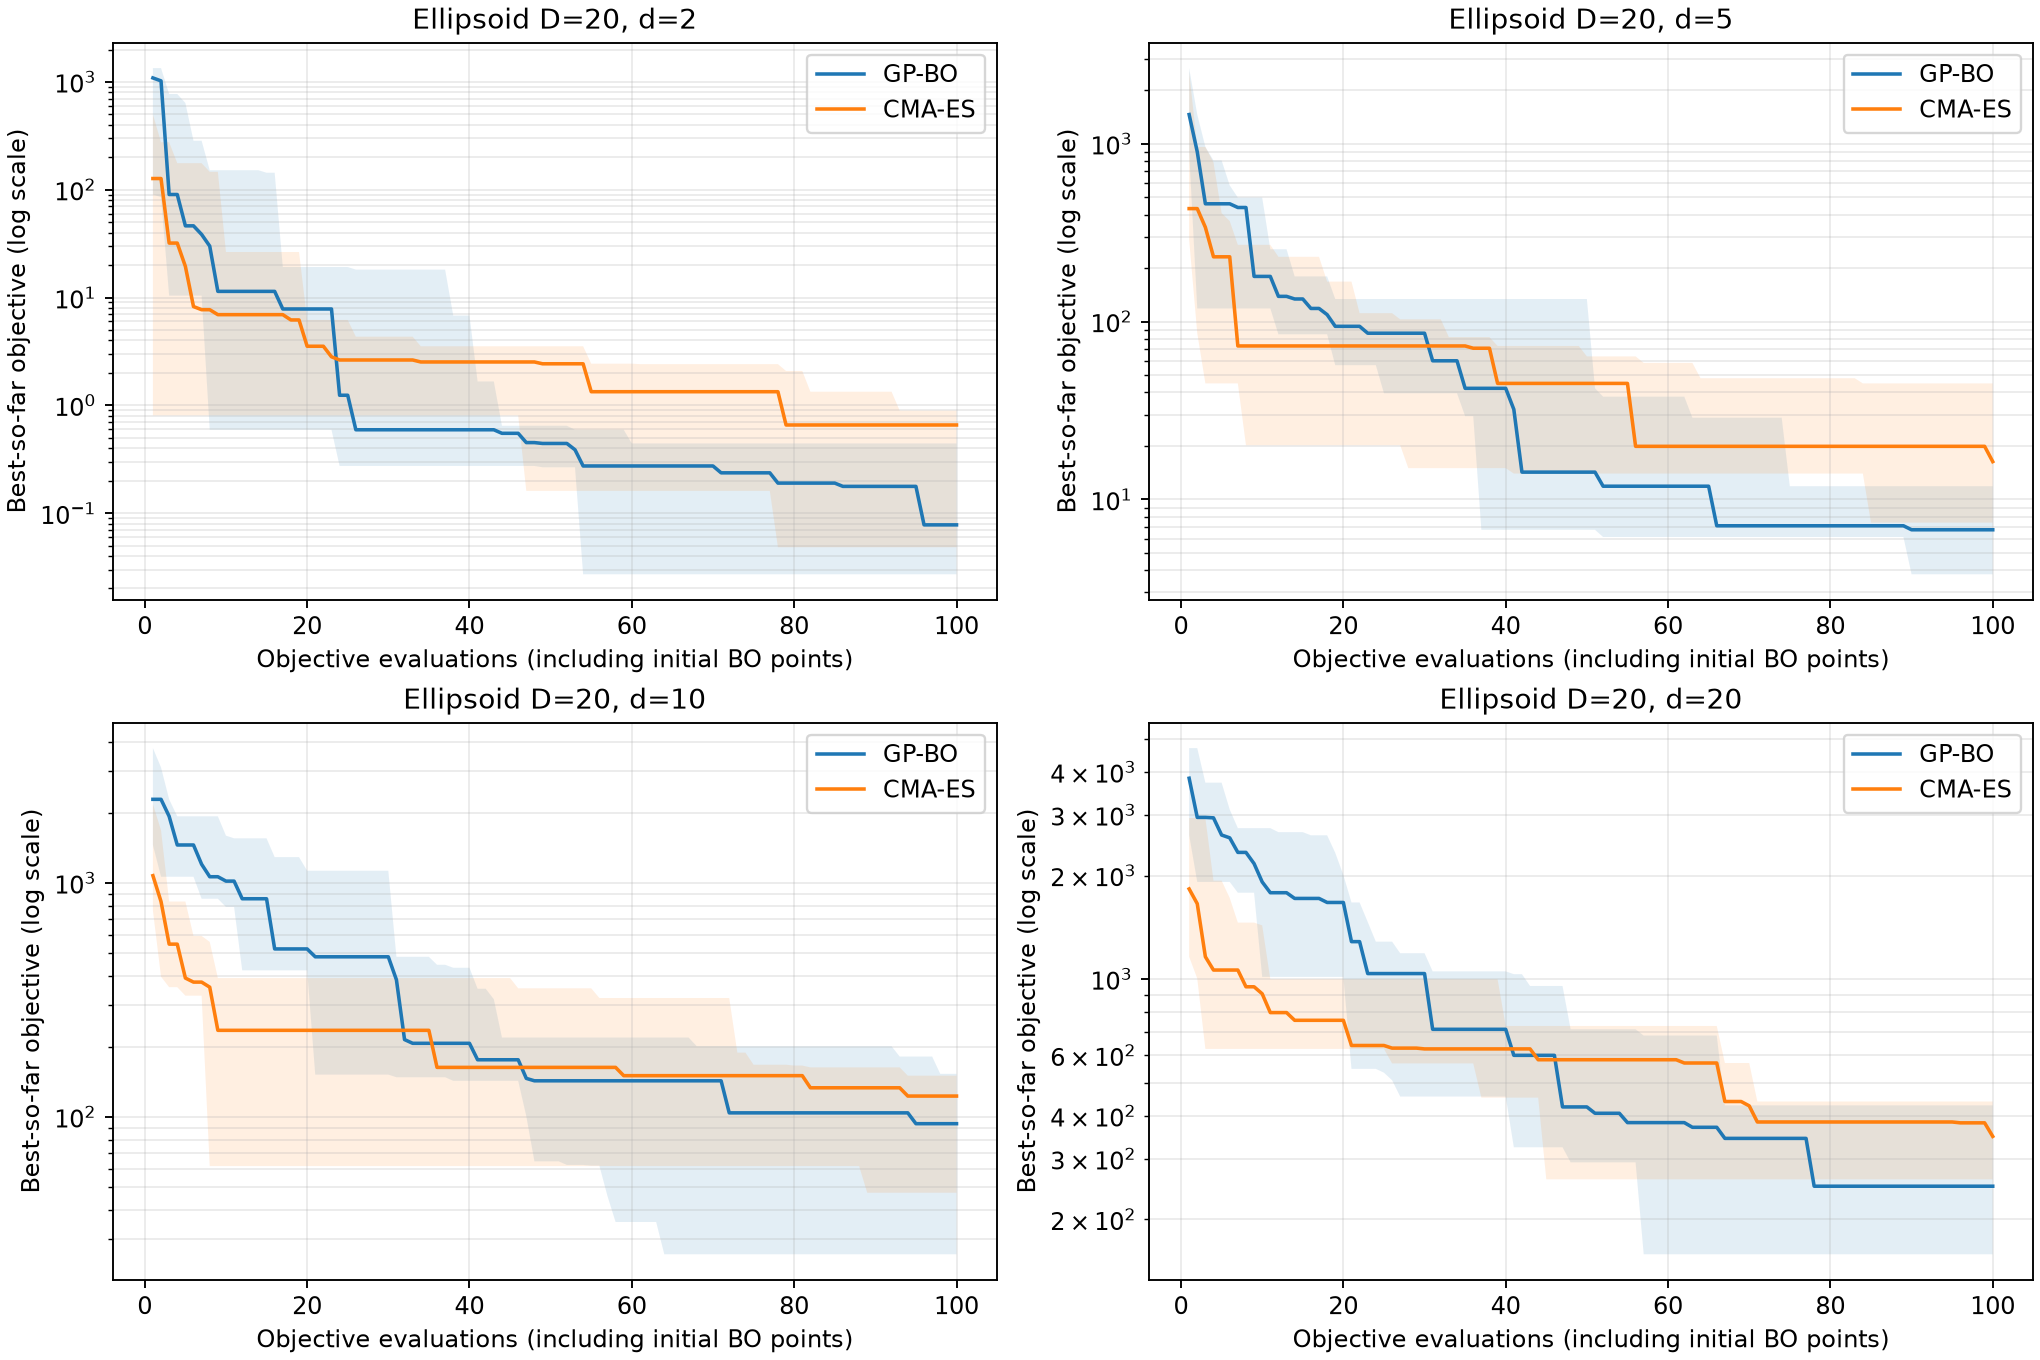

In [10]:
result_dir = Path('results/person4')
summary_file = result_dir / 'run_summary.csv'
raw_file = result_dir / 'evaluations.csv'

if summary_file.exists() and raw_file.exists():
    summary = pd.read_csv(summary_file)
    raw = pd.read_csv(raw_file)
    print('Runs found:', len(summary), '| objective evaluations logged:', len(raw))
    incomplete = summary[summary['n_evals'] != CONFIG.budget]
    if len(incomplete):
        print('WARNING: not all runs reached 100 evaluations:')
        display(incomplete[['algorithm','d','seed','n_evals','termination_reason']])
    else:
        print('All recorded runs used their full evaluation budgets.')

    finished = summary[summary['n_evals'] == CONFIG.budget]
    if not finished.empty:
        comparison = (finished.groupby(['d', 'algorithm'])['best_value']
                      .agg(['count','median','mean','min','max'])
                      .reset_index())
        display(comparison)
        print('Smaller final best-so-far objective is better.')
    plot_results(raw, result_dir / 'ellipsoid_effective_curves.png', CONFIG)
    display(Image(filename=str(result_dir / 'ellipsoid_effective_curves.png')))
else:
    print('No official results yet. Change RUN_FULL to True in Section 7 and run that cell.')


## 9. Expected files and short initial observations

Run outputs (created automatically; **no separate scripts required**)

| File | Contents |
|---|---|
| `results/person4/evaluations.csv` | Every evaluation, objective value, best-so-far, elapsed time, full `x_json` input vector |
| `results/person4/run_summary.csv` | One record per algorithm/dimension/seed run, final objective, runtime, count, termination |
| `results/person4/run_metadata.jsonl` | Complete configuration, weight vector, error traceback (if any) per run |
| `results/person4/settings.json` | Exact experiment and package versions |
| `results/person4/ellipsoid_effective_curves.png` | Four convergence panels, one for each effective dimension |

**3–5-sentence observation template** (fill using actual results)

> With ambient dimension held at 20, [describe how the final best values change as the effective dimension increases from 2 to 20]. After 100 evaluations, [algorithm] achieved a lower median best-so-far objective at d = [value], while [compare results at another d]. The gap between the algorithms [widened/narrowed/reversed/remained similar] across effective dimensions. Because these are five-seed pilot results, we regard the observed ranking as preliminary. The next phase could examine longer evaluation budgets or alternative group-approved surrogate and CMA-ES settings.

**Cross-check**  The `(D=20, d=20)` Ellipsoid experiment should match Person 2's objective and be reproducible with the same settings and seed mapping. This first phase excludes BBOB, rotations, random embeddings and formal hypothesis tests, as specified in the assignment.